# Check the results of the Desc metadetect shear matching

In [1]:
# Standard imports
import matplotlib.pyplot as plt
import numpy as np
import tables_io
import hpmcm

## Configuration

Set the tract number and define input file paths.

In [2]:
tract = 8006

# Load shear catalogs and match output tables
shear_desc_in = tables_io.read(f'{tract}/mdet-run-{tract}.parq')
shear_desc_ns = tables_io.read(f'{tract}/mdet-run-reduced_uncleaned_{tract}_ns.parq')
shear_desc_1m = tables_io.read(f'{tract}/mdet-run-reduced_uncleaned_{tract}_1m.parq')
shear_desc_1p = tables_io.read(f'{tract}/mdet-run-reduced_uncleaned_{tract}_1p.parq')
shear_desc_obj_stats = tables_io.read(f'{tract}/desc_md_match_object_stats.pq')
shear_desc_obj_assoc = tables_io.read(f'{tract}/desc_md_match_object_assoc.pq')
input_files = [
    f'{tract}/mdet-run-reduced_uncleaned_{tract}_ns.parq',
    f'{tract}/mdet-run-reduced_uncleaned_{tract}_1m.parq',
    f'{tract}/mdet-run-reduced_uncleaned_{tract}_1p.parq',
]    
catalog_ids = [0, 1, 2]

column_list None
column_list None
column_list None
column_list None
column_list None
column_list None


## Validation plots — positional checks

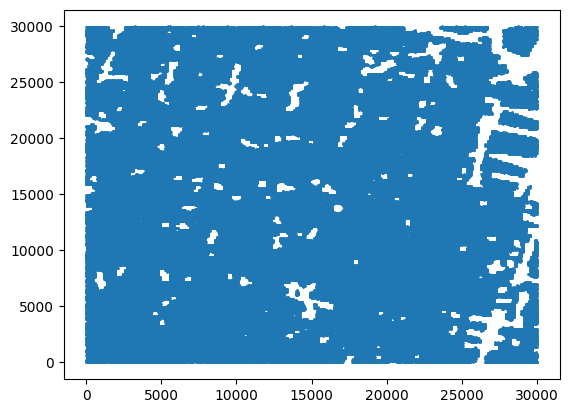

In [3]:
_ = plt.scatter(shear_desc_obj_stats.x_pix, shear_desc_obj_stats.y_pix, s=1)

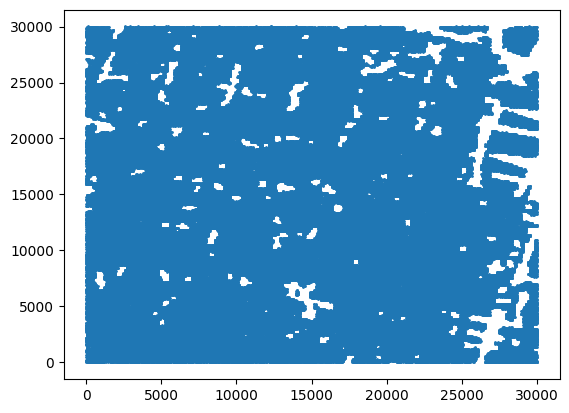

In [4]:
_ = plt.scatter(shear_desc_ns.x_pix, shear_desc_ns.y_pix, s=1)

In [5]:
# Join source catalog data onto the object stats table
joined_shear_obj_full = hpmcm.output_tables.buildJoinedObjectTable(
    shear_desc_obj_stats,
    shear_desc_obj_assoc,
    input_files,
    catalog_ids,
)

In [6]:
center_mask = np.bitwise_and(np.fabs(joined_shear_obj_full.x_cent - 75) < 75, np.fabs(joined_shear_obj_full.y_cent - 75) < 75)


In [7]:
joined_shear_obj = joined_shear_obj_full[center_mask]
joined_shear_obj_edge = joined_shear_obj_full[~center_mask]

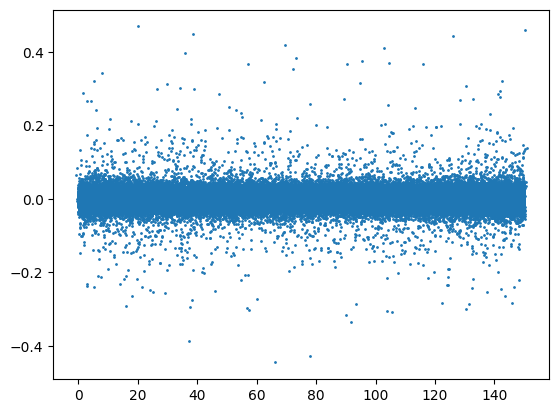

In [8]:
_ = plt.scatter(joined_shear_obj.y_cell_coadd_0, 3600*(joined_shear_obj.ra - joined_shear_obj.ra_0), s=1)

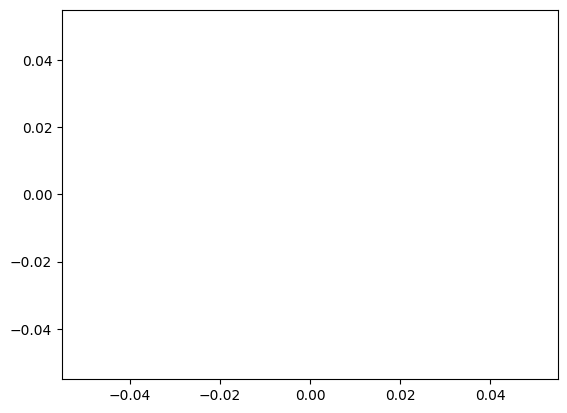

In [9]:
_ = plt.scatter(joined_shear_obj_edge.x_cent, joined_shear_obj_edge.y_cent, s=1)

In [10]:
joined_shear_obj.x_cent

0          18.492682
1          79.353026
2         138.340155
3         105.156771
4         148.007565
             ...    
320868    140.493024
320869     85.986360
320870     60.862677
320871      3.056755
320872     85.897359
Name: x_cent, Length: 320873, dtype: float64

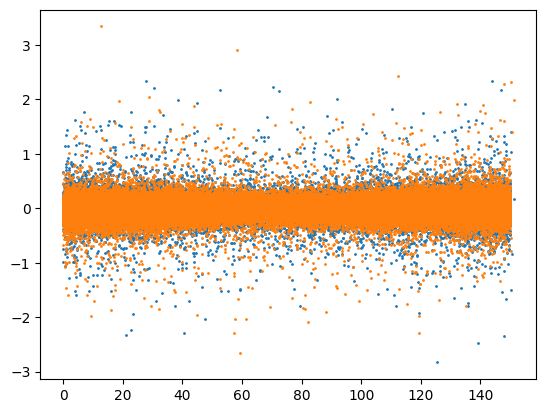

In [11]:
_ = plt.scatter(joined_shear_obj.x_cell_coadd_0, joined_shear_obj.x_pix - joined_shear_obj.x_pix_1, s=1)
_ = plt.scatter(joined_shear_obj.x_cell_coadd_0, joined_shear_obj.x_pix - joined_shear_obj.x_pix_2, s=1)

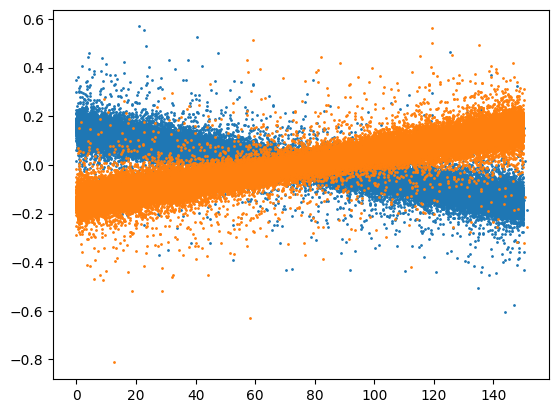

In [12]:
_ = plt.scatter(joined_shear_obj.x_cell_coadd_0, 3600*(joined_shear_obj.ra - joined_shear_obj.ra_1), s=1)
_ = plt.scatter(joined_shear_obj.x_cell_coadd_0, 3600*(joined_shear_obj.ra - joined_shear_obj.ra_2), s=1)

In [13]:
cut = np.bitwise_and(joined_shear_obj.n_sib_objects==1, joined_shear_obj.n_sib_srcs>3)
print(cut.sum())

0


In [14]:
good_mask = joined_shear_obj.catalog_mask == 7
bad_mask = joined_shear_obj.catalog_mask != 7
good_sub = joined_shear_obj[good_mask]
bad_sub = joined_shear_obj[bad_mask]
missing_ns_mask = np.bitwise_and(joined_shear_obj.catalog_mask, 1) != 1
missing_1m_mask = np.bitwise_and(joined_shear_obj.catalog_mask, 2) != 2
missing_1p_mask = np.bitwise_and(joined_shear_obj.catalog_mask, 4) != 4
missing_ns = joined_shear_obj[missing_ns_mask]
missing_1m = joined_shear_obj[missing_1m_mask]
missing_1p = joined_shear_obj[missing_1p_mask]
dense_mask = np.bitwise_and(joined_shear_obj.n_sib_objects>1, joined_shear_obj.n_sib_srcs>3)
missing_1_mask = np.bitwise_and(joined_shear_obj.n_src==2, joined_shear_obj.n_unique==2)
missing_2_mask = np.bitwise_and(joined_shear_obj.n_src==1, joined_shear_obj.n_unique==1)
confused_mask = np.bitwise_and(bad_mask, dense_mask)

missing_1 = joined_shear_obj[missing_1_mask]
missing_2 = joined_shear_obj[missing_2_mask]
dense = joined_shear_obj[dense_mask]
confused = joined_shear_obj[confused_mask]


/Users/echarles/miniconda3/envs/hpmcm/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


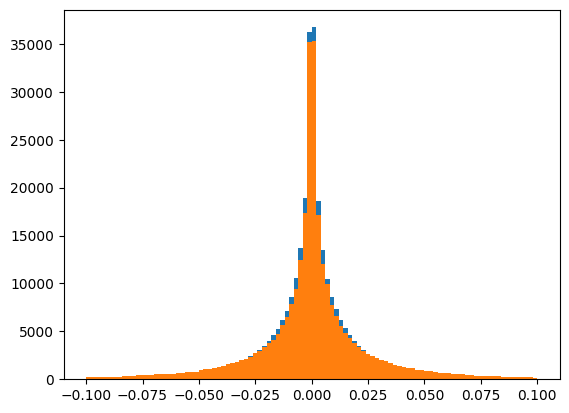

In [15]:
#_ = plt.hist((good_sub.flux_r_1 - good_sub.flux_r_0)/good_sub.flux_r_0, bins=np.linspace(-0.1, 0.1, 101))
#_ = plt.yscale('log')
_ = plt.hist(-2.5*np.log10((good_sub.flux_r_0 * good_sub.flux_i_1) / (good_sub.flux_r_1 * good_sub.flux_i_0)),  bins=np.linspace(-0.1, 0.1, 101))
#_ = plt.hist(-2.5*np.log10((good_sub.flux_r_0 * good_sub.flux_i_2) / (good_sub.flux_r_2 * good_sub.flux_i_0)),  bins=np.linspace(-0.1, 0.1, 101))
_ = plt.hist(-2.5*np.log10((good_sub.flux_i_0 * good_sub.flux_z_1) / (good_sub.flux_i_1 * good_sub.flux_z_0)),  bins=np.linspace(-0.1, 0.1, 101))
#_ = plt.hist(-2.5*np.log10((good_sub.flux_i_0 * good_sub.flux_z_2) / (good_sub.flux_i_2 * good_sub.flux_z_0)),  bins=np.linspace(-0.1, 0.1, 101))


In [16]:
dense_mask.sum()
confused_mask.sum()

np.int64(162)

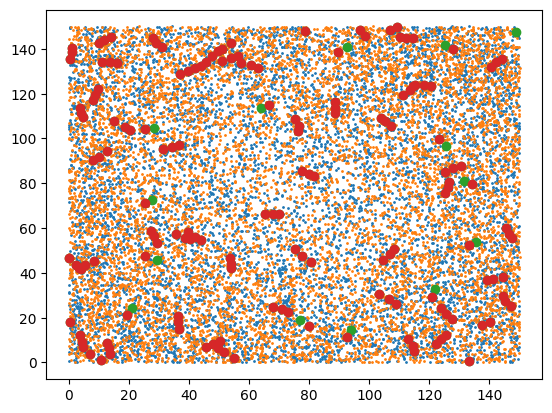

In [17]:
#_ = plt.scatter(good_sub.x_cent[::5], good_sub.y_cent[::5], s=1)
#_ = plt.scatter(bad_sub.x_cent[::5], bad_sub.y_cent[::5], s=1)
#_ = plt.scatter(missing_1.x_cent, missing_1.y_cent, s=1)
_ = plt.scatter(missing_1.x_cent, missing_1.y_cent, s=1)
_ = plt.scatter(missing_2.x_cent, missing_2.y_cent, s=1)
_ = plt.scatter(dense.x_cent, dense.y_cent)
_ = plt.scatter(confused.x_cent, confused.y_cent)

#_ = plt.scatter(missing_4.x_cent, missing_4.y_cent, s=1)

In [18]:
list(confused.columns)

['object_id',
 'cluster_id',
 'n_unique',
 'n_src',
 'dist_rms',
 'ra',
 'dec',
 'x_cent',
 'y_cent',
 'x_pix',
 'y_pix',
 'snr',
 'snr_rms',
 'cell_idx',
 'has_ref_cat',
 'catalog_mask',
 'n_sib_objects',
 'n_sib_srcs',
 'recurse',
 'patch_x_0',
 'patch_y_0',
 'ra_0',
 'dec_0',
 'id_0',
 's2n_0',
 'x_cell_coadd_0',
 'y_cell_coadd_0',
 'x_pix_0',
 'y_pix_0',
 'g1_0',
 'g2_0',
 'cell_idx_x_0',
 'cell_idx_y_0',
 'shear_0',
 'meta_step_0',
 'flux_r_0',
 'flux_i_0',
 'flux_z_0',
 'flux_err_r_0',
 'flux_err_i_0',
 'flux_err_z_0',
 'snr_0',
 'g_1_0',
 'g_2_0',
 'patch_x_1',
 'patch_y_1',
 'ra_1',
 'dec_1',
 'id_1',
 's2n_1',
 'x_cell_coadd_1',
 'y_cell_coadd_1',
 'x_pix_1',
 'y_pix_1',
 'g1_1',
 'g2_1',
 'cell_idx_x_1',
 'cell_idx_y_1',
 'shear_1',
 'meta_step_1',
 'flux_r_1',
 'flux_i_1',
 'flux_z_1',
 'flux_err_r_1',
 'flux_err_i_1',
 'flux_err_z_1',
 'snr_1',
 'g_1_1',
 'g_2_1',
 'patch_x_2',
 'patch_y_2',
 'ra_2',
 'dec_2',
 'id_2',
 's2n_2',
 'x_cell_coadd_2',
 'y_cell_coadd_2',
 'x_pix

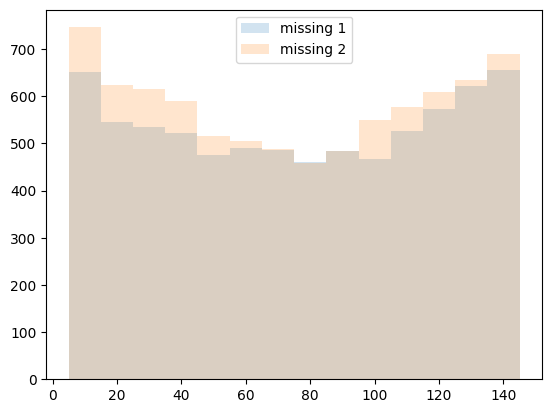

In [19]:
#_ = plt.hist(joined_shear_obj.x_cent, bins=np.linspace(5, 145, 15))
_ = plt.hist(missing_1.x_cent, bins=np.linspace(5, 145, 15), alpha=0.2, label='missing 1')
_ = plt.hist(missing_2.x_cent, bins=np.linspace(5, 145, 15), alpha=0.2, label='missing 2')

#_ = plt.yscale('log')
_ = plt.legend()

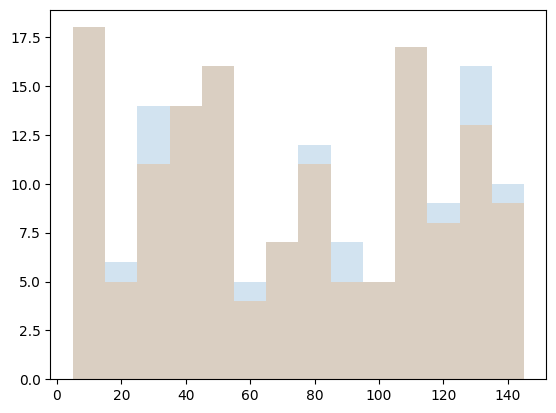

In [20]:
_ = plt.hist(dense.x_cent, bins=np.linspace(5, 145, 15), alpha=0.2, label='dense')
_ = plt.hist(confused.x_cent, bins=np.linspace(5, 145, 15), alpha=0.2, label='confused')

In [21]:
def plot_missing_v_snr(missing):
    snrs = np.linspace(4, 8, 5)
    for i in range(4):
        snr_mask = np.bitwise_and(missing.snr > snrs[i], missing.snr <= snrs[i+1])
        _ = plt.hist(missing[snr_mask].x_cent, bins=np.linspace(5, 145, 15), alpha=0.2, label=f"{snrs[i]:.2f} - {snrs[i+1]:.2f}")
    _  = plt.legend()
    return plt.gcf()

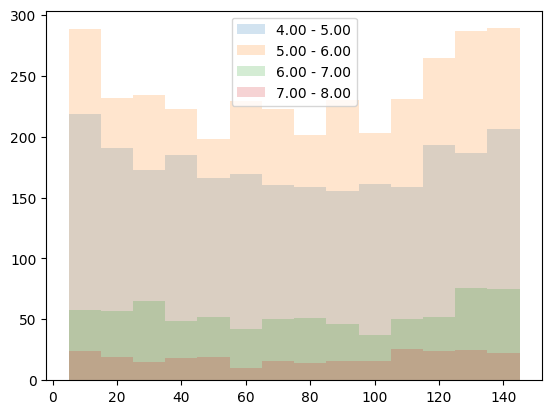

In [22]:
_ = plot_missing_v_snr(missing_1)

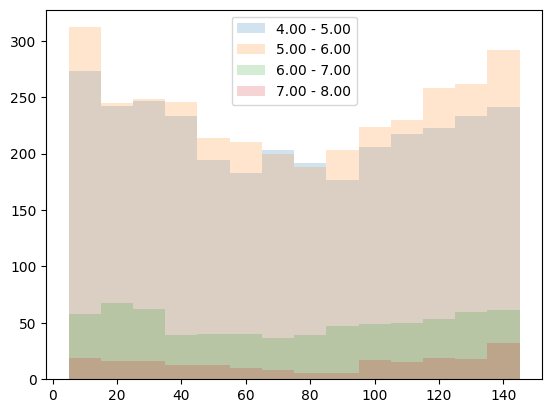

In [23]:
_ = plot_missing_v_snr(missing_2)

In [24]:
print('good', np.bitwise_and(joined_shear_obj.n_src==3, joined_shear_obj.n_unique==3).sum())
print('conf', (joined_shear_obj.n_src != joined_shear_obj.n_unique).sum())
print('missing 1', np.bitwise_and(joined_shear_obj.n_src==2, joined_shear_obj.n_unique==2).sum())
print('missing 2', np.bitwise_and(joined_shear_obj.n_src==1, joined_shear_obj.n_unique==1).sum())
print('split', np.bitwise_and(joined_shear_obj.n_sib_objects>1, joined_shear_obj.n_sib_srcs==3).sum())
print('weird', np.bitwise_and(joined_shear_obj.n_sib_objects>1, joined_shear_obj.n_sib_srcs>3).sum())
print('weird', np.bitwise_and(joined_shear_obj.n_sib_objects>1, joined_shear_obj.n_sib_srcs<3).sum())


good 303909
conf 0
missing 1 8139
missing 2 8825
split 0
weird 176
weird 0


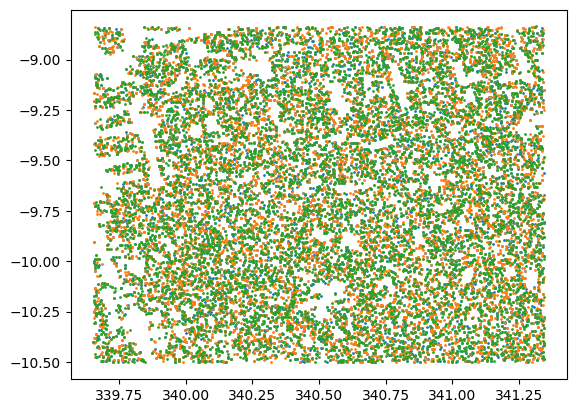

In [25]:
_ = plt.scatter(missing_ns.ra, missing_ns.dec, s=1)
_ = plt.scatter(missing_1m.ra, missing_1m.dec, s=1)
_ = plt.scatter(missing_1p.ra, missing_1p.dec, s=1)

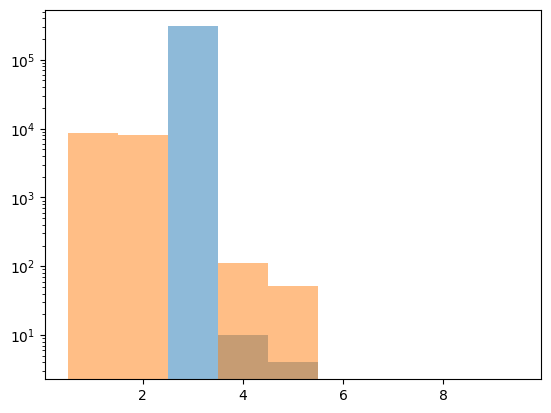

In [26]:
_ = plt.hist(good_sub.n_sib_srcs, bins=np.linspace(0.5, 9.5, 10), alpha=0.5)
_ = plt.hist(bad_sub.n_sib_srcs, bins=np.linspace(0.5, 9.5, 10), alpha=0.5)

_ = plt.yscale('log')

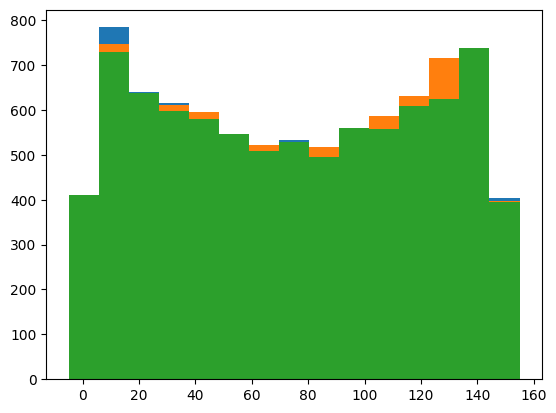

In [27]:
_ = plt.hist(missing_ns.x_cent, bins=np.linspace(-5, 155, 16))
_ = plt.hist(missing_1m.x_cent, bins=np.linspace(-5, 155, 16))
_ = plt.hist(missing_1p.x_cent, bins=np.linspace(-5, 155, 16))

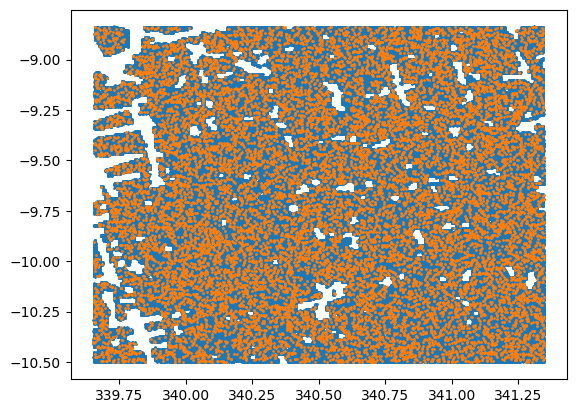

In [28]:
_ = plt.scatter(good_sub.ra, good_sub.dec, s=1)
_ = plt.scatter(bad_sub.ra, bad_sub.dec, s=1)

In [ ]:
_ = plt.scatter(good_sub.x_cent[::5], good_sub.y_cent[::5], s=1)
_ = plt.scatter(bad_sub.x_cent[::5], bad_sub.y_cent[::5], s=1)

In [ ]:
_ = plt.hist2d(3600*(good_sub.ra-good_sub.ra_0), 3600*(good_sub.dec-good_sub.dec_0),
               bins=(np.linspace(-0.4, 0.4, 81), np.linspace(-0.4, 0.4, 81)), norm='log')

In [ ]:
_ = plt.hist(good_sub.dist_rms, bins=np.linspace(0, 0.4, 201))
_ = plt.yscale('log')

In [ ]:
dist_0 = np.sqrt(good_sub.x_pix - good_sub.x_pix_0)**2 + (good_sub.y_pix - good_sub.y_pix_0)**2
dist_1 = np.sqrt(good_sub.x_pix - good_sub.x_pix_1)**2 + (good_sub.y_pix - good_sub.y_pix_1)**2
dist_2 = np.sqrt(good_sub.x_pix - good_sub.x_pix_2)**2 + (good_sub.y_pix - good_sub.y_pix_2)**2

dist_0_b = np.sqrt(bad_sub.x_pix - bad_sub.x_pix_0)**2 + (bad_sub.y_pix - bad_sub.y_pix_0)**2
dist_1_b = np.sqrt(bad_sub.x_pix - bad_sub.x_pix_1)**2 + (bad_sub.y_pix - bad_sub.y_pix_1)**2
dist_2_b = np.sqrt(bad_sub.x_pix - bad_sub.x_pix_2)**2 + (bad_sub.y_pix - bad_sub.y_pix_2)**2

In [ ]:
_ = plt.scatter(good_sub.y_cent, good_sub.x_pix - good_sub.x_pix_0, s=1)
_ = plt.scatter(good_sub.y_cent, good_sub.x_pix - good_sub.x_pix_1, s=1)
_ = plt.scatter(good_sub.y_cent, good_sub.x_pix - good_sub.x_pix_2, s=1)

In [ ]:
_ = plt.scatter(good_sub.x_cent, good_sub.x_pix - good_sub.x_pix_0, s=1)
_ = plt.scatter(good_sub.x_cent, good_sub.x_pix - good_sub.x_pix_1, s=1)
_ = plt.scatter(good_sub.x_cent, good_sub.x_pix - good_sub.x_pix_2, s=1)

In [ ]:
#_ = plt.hist2d(good_sub.x_cent, good_sub.x_pix - good_sub.x_pix_0, bins=(np.linspace(0, 150, 151), np.linspace(-2, 2, 101)), norm='log')
_ = plt.hist2d(good_sub.x_cent, good_sub.x_pix_0 - good_sub.x_pix_1, bins=(np.linspace(0, 150, 151), np.linspace(-2, 2, 101)), norm='log')
#_ = plt.hist2d(good_sub.x_cent, good_sub.x_pix_1 - good_sub.x_pix_2, bins=(np.linspace(0, 150, 151), np.linspace(-2, 2, 101)), norm='log')

In [ ]:
_ = plt.scatter(good_sub.x_cent, good_sub.y_pix - good_sub.y_pix_0, s=1)
_ = plt.scatter(good_sub.x_cent, good_sub.y_pix - good_sub.y_pix_1, s=1)
_ = plt.scatter(good_sub.x_cent, good_sub.y_pix - good_sub.y_pix_2, s=1)

In [ ]:
_ = plt.hist(dist_0, bins=np.linspace(0, 1.4, 201), alpha=0.2)
_ = plt.hist(dist_1, bins=np.linspace(0, 1.4, 201), alpha=0.2)
_ = plt.hist(dist_2, bins=np.linspace(0, 1.4, 201), alpha=0.2)
_ = plt.yscale('log')

In [ ]:
_ = plt.hist(dist_0_b, bins=np.linspace(0, 1.4, 201), alpha=0.2)
_ = plt.hist(dist_1_b, bins=np.linspace(0, 1.4, 201), alpha=0.2)
_ = plt.hist(dist_2_b, bins=np.linspace(0, 1.4, 201), alpha=0.2)
_ = plt.yscale('log')

In [ ]:
_ = plt.hist2d(3600*(bad_sub.ra-bad_sub.ra_0), 3600*(bad_sub.dec-bad_sub.dec_0),
               bins=(np.linspace(-0.4, 0.4, 81), np.linspace(-0.4, 0.4, 81)), norm='log')

In [ ]:
_ = plt.hist(shear_desc_ns.x_cell_coadd, bins=np.linspace(-5, 155, 16))
_ = plt.hist(shear_desc_1m.x_cell_coadd, bins=np.linspace(-5, 155, 16))
_ = plt.hist(shear_desc_1p.x_cell_coadd, bins=np.linspace(-5, 155, 16))

In [ ]:
_ = plt.hist(joined_shear_obj.x_cent, bins=np.linspace(-5, 155, 161))
_ = plt.hist(good_sub.x_cent, bins=np.linspace(-5, 155, 161))
_ = plt.hist(bad_sub.x_cent, bins=np.linspace(-5, 155, 161))

In [ ]:
_ = plt.hist(good_sub.y_cent, bins=np.linspace(-5, 155, 161))
_ = plt.hist(bad_sub.y_cent, bins=np.linspace(-5, 155, 161))

In [ ]:
_ = plt.hist(joined_shear_obj.catalog_mask, bins=np.linspace(0.5, 7.5, 8), alpha=0.2)
_ = plt.hist(joined_shear_obj_edge.catalog_mask, bins=np.linspace(0.5, 7.5, 8), alpha=0.2)
_ = plt.yscale('log')